<a href="https://colab.research.google.com/github/eyramana/MLA0201-FUNDAMENTALS-OF-MACHINE-LEARNING/blob/main/Ramana_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training Data:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes

Initial Hypothesis: ['0', '0', '0', '0', '0', '0']
After Example 1: ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
After Example 2: ['Sunny', 'Warm', 'Any', 'Strong', 'Warm', 'Same']
After Example 4: ['Sunny', 'Warm', 'Any', 'Strong', 'Any', 'Any']

Final Most Specific Hypothesis:
['Sunny', 'Warm', 'Any', 'Strong', 'Any', 'Any']


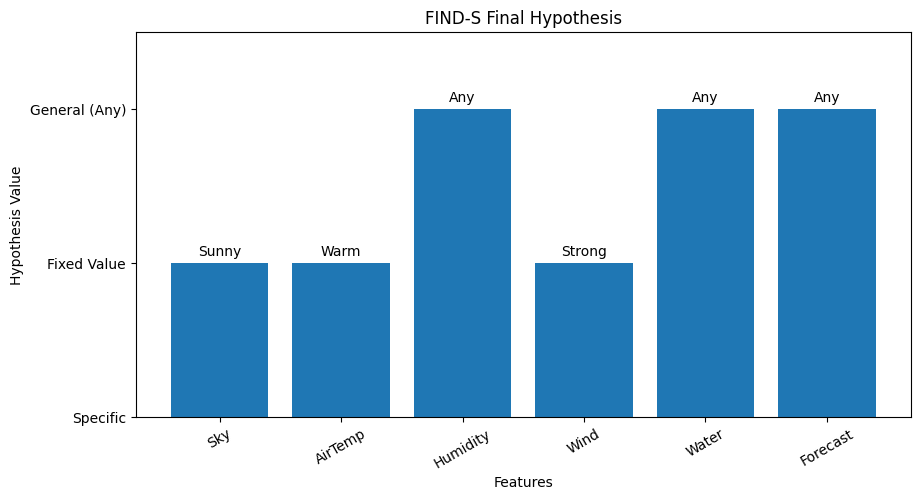

In [ ]:
# Experiment No: 1
# Question: Implement and demonstrate the FIND-S algorithm for finding
# the most specific hypothesis based on a given set of training data samples.
import pandas as pd
import matplotlib.pyplot as plt

# Training data
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

print("Training Data:")
print(df)

# FIND-S algorithm (using 'Any' instead of '?')
hypothesis = ['0'] * 6

print("\nInitial Hypothesis:", hypothesis)

for index, row in df.iterrows():
    # Consider only positive examples
    if row['EnjoySport'] == 'Yes':
        for i in range(6):
            if hypothesis[i] == '0':
                hypothesis[i] = row.iloc[i]
            elif hypothesis[i] != row.iloc[i]:
                hypothesis[i] = 'Any'
        print(f"After Example {index + 1}: {hypothesis}")

print("\nFinal Most Specific Hypothesis:")
print(hypothesis)

# -----------------------------
# Matplotlib Visualization
# -----------------------------

features = ['Sky', 'AirTemp', 'Humidity',
            'Wind', 'Water', 'Forecast']

# Convert hypothesis into numeric values for visualization
values = []
for h in hypothesis:
    if h == 'Any':
        values.append(2)
    elif h == '0':
        values.append(0)
    else:
        values.append(1)

plt.figure(figsize=(10, 5))
bars = plt.bar(features, values)

plt.title("FIND-S Final Hypothesis")
plt.xlabel("Features")
plt.ylabel("Hypothesis Value")
plt.xticks(rotation=30)

# Add labels
for bar, h in zip(bars, hypothesis):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.05,
        h,
        ha='center'
    )

plt.yticks([0, 1, 2], ['Specific', 'Fixed Value', 'General (Any)'])
plt.ylim(0, 2.5)
plt.show()

Training Data:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes

Final Specific Boundary (S):
['Sunny', 'Warm', 'Any', 'Strong', 'Any', 'Any']

Final General Boundary (G):
['Sunny', 'Any', 'Any', 'Any', 'Any', 'Any']
['Any', 'Warm', 'Any', 'Any', 'Any', 'Any']
['Any', 'Any', 'Any', 'Strong', 'Any', 'Any']


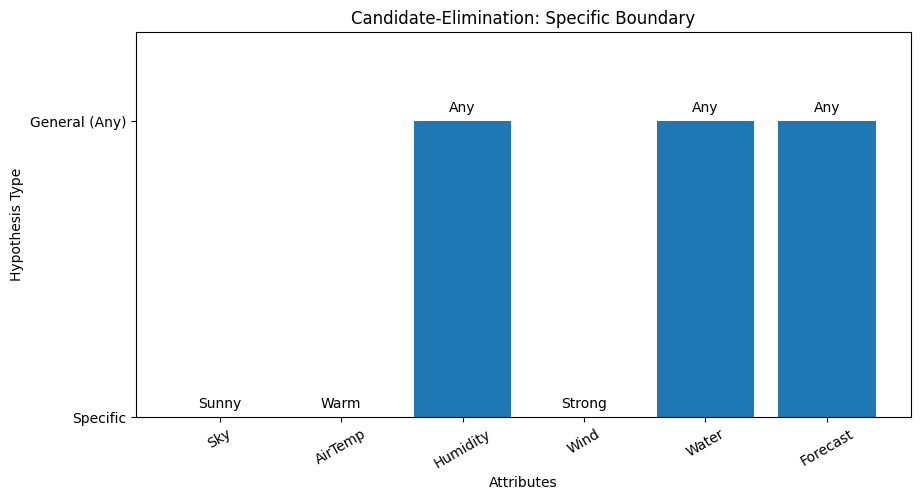

In [ ]:
# Experiment No: 2
# Question: For a given set of training data examples stored in a .CSV file,
# implement and demonstrate the Candidate-Elimination algorithm in Python
# to output a description of the set of all hypotheses consistent with
# the training examples.
# Candidate-Elimination Algorithm
# Google Colab

import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------
# 1. Create training data and save it as CSV
# -------------------------------------------------

data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

# Save as CSV
df.to_csv('enjoysport.csv', index=False)

# Read CSV file
df = pd.read_csv('enjoysport.csv')

print("Training Data:")
print(df)


# -------------------------------------------------
# 2. Candidate-Elimination Algorithm
# -------------------------------------------------

def candidate_elimination(data):

    attributes = list(data.columns[:-1])
    target = data.columns[-1]

    # Most specific hypothesis
    S = ['0'] * len(attributes)

    # Most general hypothesis (using 'Any' instead of '?')
    G = [['Any'] * len(attributes)]

    for _, example in data.iterrows():

        x = list(example[:-1])
        label = example[target]

        # -----------------------------------------
        # Positive Example
        # -----------------------------------------
        if label == 'Yes':

            # Remove inconsistent hypotheses from G
            G = [
                g for g in G
                if all(g[i] == 'Any' or g[i] == x[i] for i in range(len(x)))
            ]

            # Generalize S
            for i in range(len(x)):

                if S[i] == '0':
                    S[i] = x[i]

                elif S[i] != x[i]:
                    S[i] = 'Any'

            # Remove G hypotheses that are less general than S
            G = [
                g for g in G
                if all(g[i] == 'Any' or S[i] == 'Any' or g[i] == S[i]
                       for i in range(len(x)))
            ]

        # -----------------------------------------
        # Negative Example
        # -----------------------------------------
        else:

            new_G = []

            for g in G:

                # If G covers the negative example,
                # specialize it
                if all(g[i] == 'Any' or g[i] == x[i]
                       for i in range(len(x))):

                    for i in range(len(x)):

                        if g[i] == 'Any':
                            new_h = g.copy()

                            if S[i] != 'Any' and S[i] != '0':
                                new_h[i] = S[i]

                                if new_h not in new_G:
                                    new_G.append(new_h)

                else:
                    new_G.append(g)

            G = new_G

    return S, G


# -------------------------------------------------
# 3. Run Algorithm
# -------------------------------------------------

S, G = candidate_elimination(df)

print("\nFinal Specific Boundary (S):")
print(S)

print("\nFinal General Boundary (G):")

for g in G:
    print(g)


# -------------------------------------------------
# 4. Matplotlib Visualization
# -------------------------------------------------

features = list(df.columns[:-1])

# Convert hypothesis values to numbers
# 0 = specific value
# 1 = Any
values = []

for value in S:
    if value == 'Any':
        values.append(1)
    else:
        values.append(0)

plt.figure(figsize=(10, 5))

bars = plt.bar(features, values)

plt.title("Candidate-Elimination: Specific Boundary")
plt.xlabel("Attributes")
plt.ylabel("Hypothesis Type")

plt.xticks(rotation=30)
plt.yticks([0, 1], ['Specific', 'General (Any)'])

# Display hypothesis values on bars
for bar, value in zip(bars, S):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.03,
        value,
        ha='center'
    )

plt.ylim(0, 1.3)
plt.show()

### ID3 Decision Tree Algorithm Implementation
In this section, we implement the ID3 algorithm from scratch to construct a decision tree based on Information Gain (using Entropy) and classify a new test sample.

Training Data:

     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes

Initial Hypothesis:
['0', '0', '0', '0', '0', '0']
After Example 1 : ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
After Example 2 : ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
After Example 4 : ['Sunny', 'Warm', '?', 'Strong', '?', '?']

Final Most Specific Hypothesis:
['Sunny', 'Warm', '?', 'Strong', '?', '?']


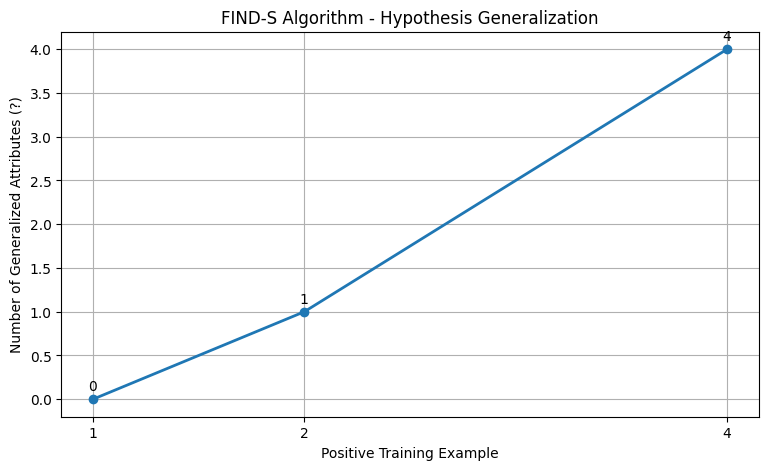

In [ ]:
# Experiment No: 3
# Question: Demonstrate the working of the decision tree based ID3 algorithm.
# Use an appropriate dataset for building the decision tree and apply
# this knowledge to classify a new sample.

import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------------
# 1. Training Dataset
# -----------------------------------------

data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

print("Training Data:\n")
print(df)


# -----------------------------------------
# 2. FIND-S Algorithm
# -----------------------------------------

features = list(df.columns[:-1])

# Initial most specific hypothesis
hypothesis = ['0'] * len(features)

# Store number of generalizations
steps = []
generalized_count = []

print("\nInitial Hypothesis:")
print(hypothesis)

count = 0

for index, row in df.iterrows():

    # Only positive examples are considered
    if row['EnjoySport'] == 'Yes':

        for i in range(len(features)):

            if hypothesis[i] == '0':
                hypothesis[i] = row[features[i]]

            elif hypothesis[i] != row[features[i]]:
                hypothesis[i] = '?'

        count += hypothesis.count('?')

        steps.append(index + 1)
        generalized_count.append(count)

        print(
            "After Example", index + 1,
            ":", hypothesis
        )


# -----------------------------------------
# 3. Final Hypothesis
# -----------------------------------------

print("\nFinal Most Specific Hypothesis:")
print(hypothesis)


# -----------------------------------------
# 4. Graph
# -----------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    steps,
    generalized_count,
    marker='o',
    linewidth=2
)

plt.title("FIND-S Algorithm - Hypothesis Generalization")
plt.xlabel("Positive Training Example")
plt.ylabel("Number of Generalized Attributes (?)")

plt.xticks(steps)

plt.grid(True)

# Display values
for x, y in zip(steps, generalized_count):
    plt.text(x, y + 0.1, str(y), ha='center')

plt.show()

Training Dataset:
     Outlook Temperature Humidity    Wind PlayTennis
0      Sunny         Hot     High    Weak         No
1      Sunny         Hot     High  Strong         No
2   Overcast         Hot     High    Weak        Yes
3       Rain        Mild     High    Weak        Yes
4       Rain        Cool   Normal    Weak        Yes
5       Rain        Cool   Normal  Strong         No
6   Overcast        Cool   Normal  Strong        Yes
7      Sunny        Mild     High    Weak         No
8      Sunny        Cool   Normal    Weak        Yes
9       Rain        Mild   Normal    Weak        Yes
10     Sunny        Mild   Normal  Strong        Yes
11  Overcast        Mild     High  Strong        Yes
12  Overcast         Hot   Normal    Weak        Yes
13      Rain        Mild     High  Strong         No

Generated ID3 Decision Tree:
{'Outlook': {'Sunny': {'Humidity': {'High': 'No', 'Normal': 'Yes'}}, 'Overcast': 'Yes', 'Rain': {'Wind': {'Weak': 'Yes', 'Strong': 'No'}}}}

New Unseen Sampl

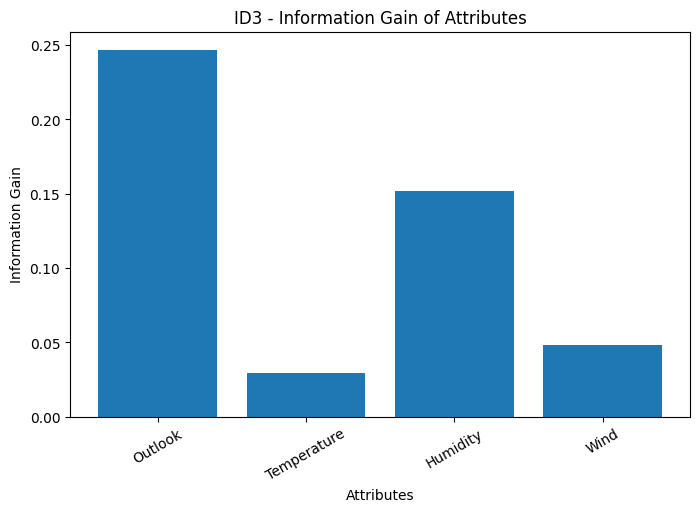

In [ ]:
# Experiment No: 4
# Question: Build an Artificial Neural Network by implementing the
# Backpropagation algorithm and test the same using appropriate datasets.

import pandas as pd
import matplotlib.pyplot as plt
from math import log2

# --------------------------------------------------
# 1. Create Dataset
# --------------------------------------------------

data = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain', 'Rain',
                'Overcast', 'Sunny', 'Sunny', 'Rain', 'Sunny', 'Overcast',
                'Overcast', 'Rain'],

    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool',
                    'Cool', 'Mild', 'Cool', 'Mild', 'Mild', 'Mild',
                    'Hot', 'Mild'],

    'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal',
                 'Normal', 'High', 'Normal', 'Normal', 'Normal', 'High',
                 'Normal', 'High'],

    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong',
             'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong',
             'Weak', 'Strong'],

    'PlayTennis': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No',
                   'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes',
                   'Yes', 'No']
}

df = pd.DataFrame(data)

print("Training Dataset:")
print(df)


# --------------------------------------------------
# 2. Entropy Function
# --------------------------------------------------

def entropy(data):

    target = data.iloc[:, -1]
    values = target.value_counts()

    total = len(target)
    result = 0

    for count in values:
        probability = count / total
        result -= probability * log2(probability)

    return result


# --------------------------------------------------
# 3. Information Gain
# --------------------------------------------------

def information_gain(data, attribute):

    total_entropy = entropy(data)

    values = data[attribute].unique()
    weighted_entropy = 0

    for value in values:

        subset = data[data[attribute] == value]

        weighted_entropy += (
            len(subset) / len(data)
        ) * entropy(subset)

    return total_entropy - weighted_entropy


# --------------------------------------------------
# 4. ID3 Algorithm
# --------------------------------------------------

def ID3(data, original_data, features):

    # If all examples belong to the same class
    if len(data.iloc[:, -1].unique()) == 1:
        return data.iloc[:, -1].iloc[0]

    # If no features remain
    if len(features) == 0:
        return original_data.iloc[:, -1].mode()[0]

    # Calculate information gain
    gains = {}

    for feature in features:
        gains[feature] = information_gain(data, feature)

    # Select feature with maximum information gain
    best_feature = max(gains, key=gains.get)

    tree = {best_feature: {}}

    remaining_features = [
        feature for feature in features
        if feature != best_feature
    ]

    # Create branches
    for value in data[best_feature].unique():

        subset = data[data[best_feature] == value]

        tree[best_feature][value] = ID3(
            subset,
            original_data,
            remaining_features
        )

    return tree


# --------------------------------------------------
# 5. Build Decision Tree
# --------------------------------------------------

features = list(df.columns[:-1])

tree = ID3(df, df, features)

print("\nGenerated ID3 Decision Tree:")
print(tree)


# --------------------------------------------------
# 6. Prediction Function
# --------------------------------------------------

def predict(query, tree, default='Yes'):

    for key in query.keys():

        if key in tree:

            try:
                result = tree[key][query[key]]

            except KeyError:
                return default

            if isinstance(result, dict):
                return predict(query, result, default)

            else:
                return result

    return default


# --------------------------------------------------
# 7. New Sample
# --------------------------------------------------

new_sample = {
    'Outlook': 'Rain',
    'Temperature': 'Cool',
    'Humidity': 'Normal',
    'Wind': 'Strong'
}

prediction = predict(new_sample, tree)

print("\nNew Unseen Sample:")
print(new_sample)

print("\nPredicted Class (PlayTennis):", prediction)


# --------------------------------------------------
# 8. Matplotlib Visualization
# --------------------------------------------------

# Show Information Gain of each attribute

gain_values = []

for feature in features:
    gain_values.append(information_gain(df, feature))

plt.figure(figsize=(8, 5))

plt.bar(features, gain_values)

plt.title("ID3 - Information Gain of Attributes")
plt.xlabel("Attributes")
plt.ylabel("Information Gain")

plt.xticks(rotation=30)

plt.show()

Training Data:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes

Final Most Specific Hypothesis:
Sky : Sunny
AirTemp : Warm
Humidity : Any Value
Wind : Strong
Water : Any Value
Forecast : Any Value


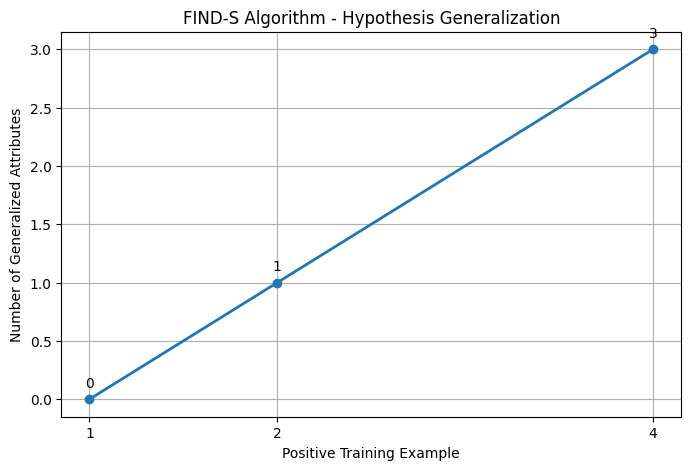

In [ ]:
# Experiment No: 5
# Question: Write a program for Implementation of K-Nearest Neighbours (K-NN) in Python.
import pandas as pd
import matplotlib.pyplot as plt

# Training data
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

# FIND-S Algorithm
features = list(df.columns[:-1])
hypothesis = ['0'] * len(features)

steps = []
generalized_count = []

for i, row in df.iterrows():

    # Consider only positive examples
    if row['EnjoySport'] == 'Yes':

        if hypothesis == ['0'] * len(features):
            hypothesis = [row[feature] for feature in features]

        else:
            for j, feature in enumerate(features):
                if hypothesis[j] != row[feature]:
                    hypothesis[j] = 'Any Value'

        steps.append(i + 1)
        generalized_count.append(
            hypothesis.count('Any Value')
        )

# Display result
print("Training Data:")
print(df)

print("\nFinal Most Specific Hypothesis:")
for feature, value in zip(features, hypothesis):
    print(feature, ":", value)

# Graph
plt.figure(figsize=(8, 5))

plt.plot(
    steps,
    generalized_count,
    marker='o',
    linewidth=2
)

plt.title("FIND-S Algorithm - Hypothesis Generalization")
plt.xlabel("Positive Training Example")
plt.ylabel("Number of Generalized Attributes")

plt.xticks(steps)
plt.grid(True)

for x, y in zip(steps, generalized_count):
    plt.text(x, y + 0.1, str(y), ha='center')

plt.show()

Actual Values: [0, 1, 0, 1, 1, 0]
Predicted Values: [np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(0)]
Accuracy: 100.0 %

Confusion Matrix:
[[3 0]
 [0 3]]


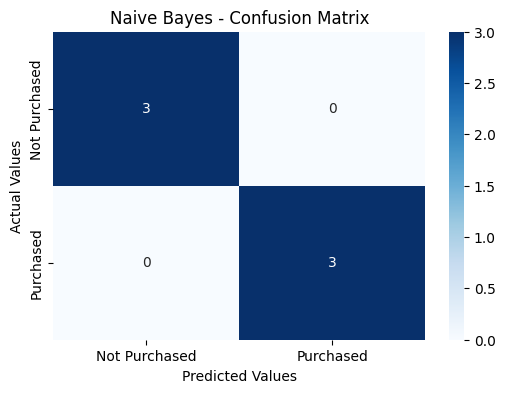

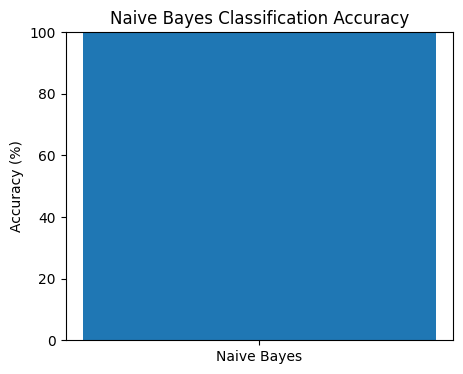


Classification Report:
               precision    recall  f1-score   support

Not Purchased       1.00      1.00      1.00         3
    Purchased       1.00      1.00      1.00         3

     accuracy                           1.00         6
    macro avg       1.00      1.00      1.00         6
 weighted avg       1.00      1.00      1.00         6



In [ ]:
# Experiment No: 6
# Question: Write a program to implement Naïve Bayes algorithm in Python
# and to display the results using confusion matrix and accuracy.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Dataset
data = {
    'Age': [22, 25, 47, 52, 46, 56, 23, 40, 60, 48,
            33, 28, 35, 50, 42, 29, 55, 31, 45, 38],
    'Salary': [20000, 25000, 60000, 80000, 65000, 90000, 22000,
               50000, 100000, 70000, 40000, 30000, 45000, 85000,
               55000, 28000, 95000, 35000, 75000, 48000],
    'Purchased': [0, 0, 1, 1, 1, 1, 0, 1, 1, 1,
                  0, 0, 0, 1, 1, 0, 1, 0, 1, 0]
}

df = pd.DataFrame(data)

# Features and target
X = df[['Age', 'Salary']]
y = df['Purchased']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Train Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Actual Values:", list(y_test))
print("Predicted Values:", list(y_pred))
print("Accuracy:", round(accuracy * 100, 2), "%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Purchased', 'Purchased'],
    yticklabels=['Not Purchased', 'Purchased']
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Naive Bayes - Confusion Matrix")
plt.show()

# Accuracy graph
plt.figure(figsize=(5, 4))
plt.bar(['Naive Bayes'], [accuracy * 100])
plt.ylabel("Accuracy (%)")
plt.title("Naive Bayes Classification Accuracy")
plt.ylim(0, 100)
plt.show()

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['Not Purchased', 'Purchased'],
    zero_division=0
))

Actual Values: [0, 1, 1]
Predicted Values: [np.int64(0), np.int64(1), np.int64(1)]
Accuracy: 100.0 %

Confusion Matrix:
[[1 0]
 [0 2]]


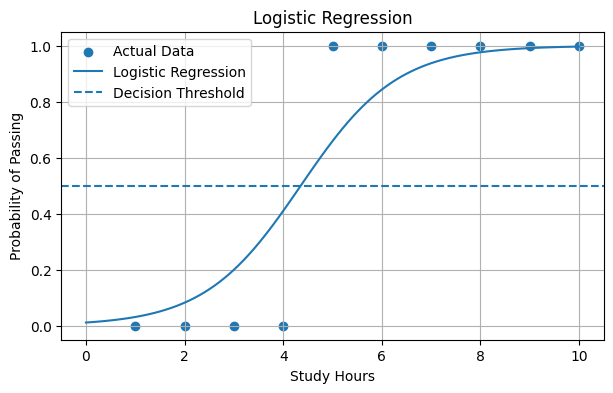

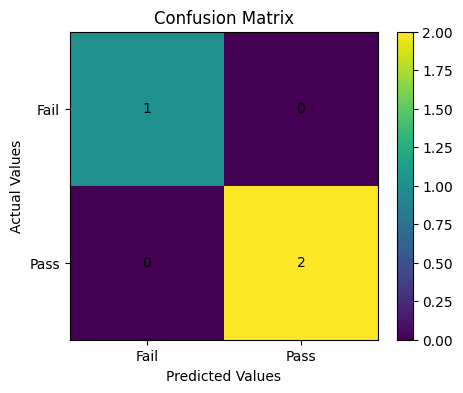


Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1
        Pass       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



In [ ]:
# Experiment No: 7
# Question: Write a program to implement Logistic Regression (LR) algorithm in Python.

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create Dataset
data = {
    'Hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Pass':  [0, 0, 0, 0, 1, 1, 1, 1, 1, 1]
}

df = pd.DataFrame(data)

# Features and Target
X = df[['Hours']]
y = df['Pass']

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Train Logistic Regression Model
model = LogisticRegression()
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Display Results
print("Actual Values:", list(y_test))
print("Predicted Values:", list(y_pred))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Plot Classification Results
plt.figure(figsize=(7, 4))
plt.scatter(df['Hours'], df['Pass'], label='Actual Data')

hours_range = pd.DataFrame({
    'Hours': [i / 10 for i in range(0, 101)]
})
probabilities = model.predict_proba(hours_range)[:, 1]

plt.plot(hours_range['Hours'], probabilities, label='Logistic Regression')
plt.axhline(0.5, linestyle='--', label='Decision Threshold')

plt.xlabel("Study Hours")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()

# Plot Confusion Matrix
plt.figure(figsize=(5, 4))
plt.imshow(cm, interpolation='nearest')
plt.title("Confusion Matrix")
plt.colorbar()
plt.xticks([0, 1], ['Fail', 'Pass'])
plt.yticks([0, 1], ['Fail', 'Pass'])
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['Fail', 'Pass'],
    zero_division=0
))

Actual Marks: [75, 40]
Predicted Marks: [75. 40.]
Mean Squared Error: 0.0
R2 Score: 1.0

Predicted Marks for 11 Study Hours: 85.0


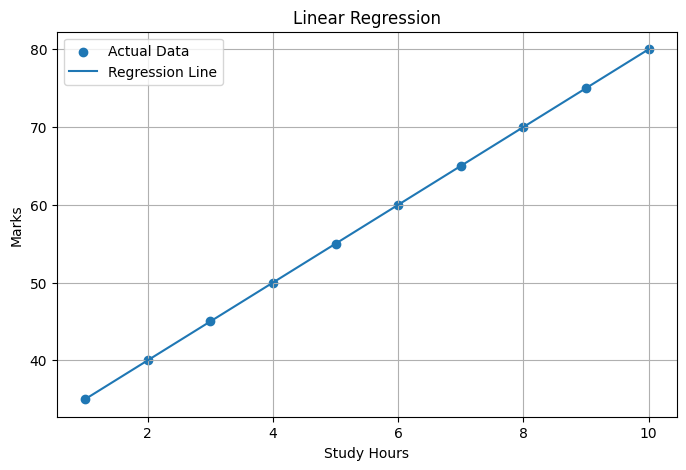

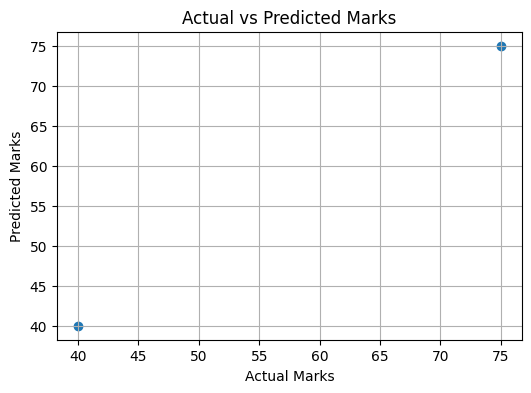

In [ ]:
# Experiment No: 8
# Question: Write a program to implement Linear Regression (LR) algorithm in Python.

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Create Dataset
data = {
    'Hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Marks': [35, 40, 45, 50, 55, 60, 65, 70, 75, 80]
}

df = pd.DataFrame(data)

# Features and Target
X = df[['Hours']]
y = df['Marks']

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict Results
y_pred = model.predict(X_test)

# Display Results
print("Actual Marks:", list(y_test))
print("Predicted Marks:", y_pred.round(2))
print("Mean Squared Error:", round(mean_squared_error(y_test, y_pred), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 2))

# Predict Marks for 11 Study Hours
new_hours = pd.DataFrame({'Hours': [11]})
predicted_marks = model.predict(new_hours)

print("\nPredicted Marks for 11 Study Hours:", round(predicted_marks[0], 2))

# Plot Regression Line
plt.figure(figsize=(8, 5))
plt.scatter(X, y, label="Actual Data")
plt.plot(X, model.predict(X), label="Regression Line")

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

# Actual vs Predicted Graph
plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Marks")
plt.grid(True)
plt.show()

Linear Regression
MSE: 196.48
R2 Score: 0.9331

Polynomial Regression
MSE: 0.2
R2 Score: 0.9999


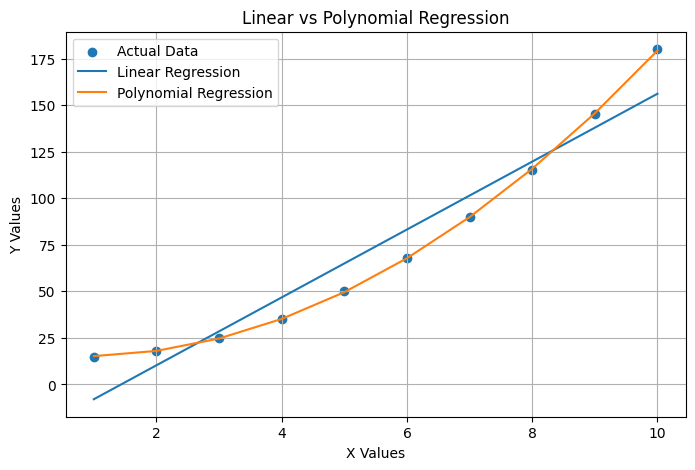

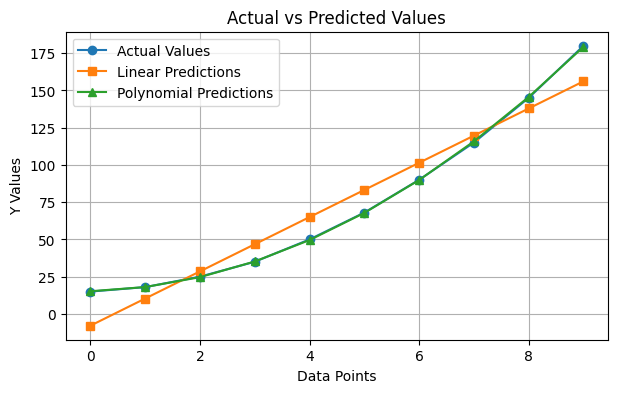

In [ ]:
# Experiment No: 9
# Question: Compare Linear and Polynomial Regression using Python.

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

# Create Dataset
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)
y = np.array([15, 18, 25, 35, 50, 68, 90, 115, 145, 180])

# Linear Regression
linear_model = LinearRegression()
linear_model.fit(X, y)
linear_pred = linear_model.predict(X)

# Polynomial Regression
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

poly_model = LinearRegression()
poly_model.fit(X_poly, y)
poly_pred = poly_model.predict(X_poly)

# Display Results
print("Linear Regression")
print("MSE:", round(mean_squared_error(y, linear_pred), 2))
print("R2 Score:", round(r2_score(y, linear_pred), 4))

print("\nPolynomial Regression")
print("MSE:", round(mean_squared_error(y, poly_pred), 2))
print("R2 Score:", round(r2_score(y, poly_pred), 4))

# Plot Comparison
plt.figure(figsize=(8, 5))
plt.scatter(X, y, label="Actual Data")
plt.plot(X, linear_pred, label="Linear Regression")
plt.plot(X, poly_pred, label="Polynomial Regression")

plt.xlabel("X Values")
plt.ylabel("Y Values")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid(True)
plt.show()

# Actual vs Predicted Comparison
plt.figure(figsize=(7, 4))
plt.plot(y, marker='o', label="Actual Values")
plt.plot(linear_pred, marker='s', label="Linear Predictions")
plt.plot(poly_pred, marker='^', label="Polynomial Predictions")

plt.xlabel("Data Points")
plt.ylabel("Y Values")
plt.title("Actual vs Predicted Values")
plt.legend()
plt.grid(True)
plt.show()

Expectation-Maximization Algorithm
Number of Clusters: 2
Cluster Means: [4.88 9.97]
Cluster Weights: [0.49 0.51]
Cluster Variances: [0.81 2.23]


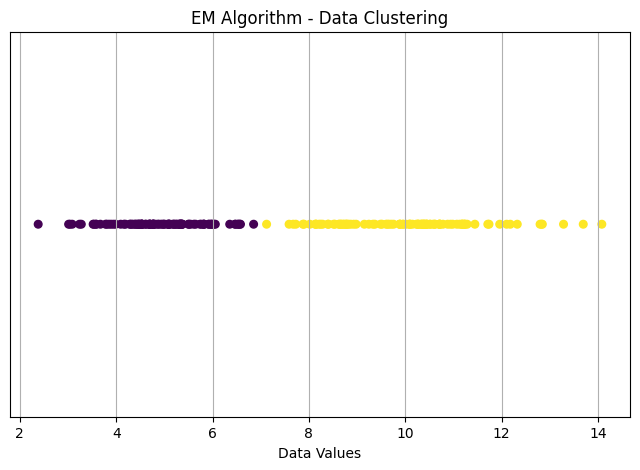

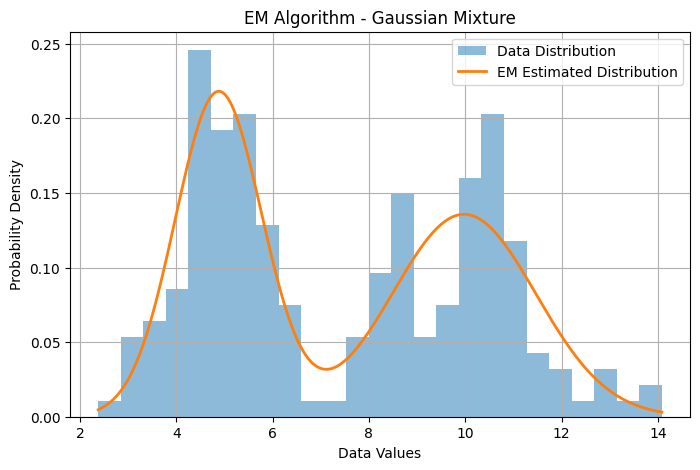

In [ ]:
# Experiment No: 10
# Question: Write a Python Program to Implement Expectation & Maximization Algorithm.

import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

# Create Dataset
np.random.seed(42)

data1 = np.random.normal(5, 1, 100)
data2 = np.random.normal(10, 1.5, 100)

X = np.concatenate([data1, data2]).reshape(-1, 1)

# Apply EM Algorithm using Gaussian Mixture Model
model = GaussianMixture(n_components=2, random_state=42)
model.fit(X)

# Predict Clusters
labels = model.predict(X)

# Display Results
print("Expectation-Maximization Algorithm")
print("Number of Clusters:", model.n_components)
print("Cluster Means:", model.means_.flatten().round(2))
print("Cluster Weights:", model.weights_.round(2))
print("Cluster Variances:", model.covariances_.flatten().round(2))

# Plot Data Clusters
plt.figure(figsize=(8, 5))

plt.scatter(X[:, 0], np.zeros(len(X)),
            c=labels, cmap='viridis', s=30)

plt.xlabel("Data Values")
plt.title("EM Algorithm - Data Clustering")
plt.yticks([])
plt.grid(True)
plt.show()

# Plot Gaussian Distributions
x_range = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
log_prob = model.score_samples(x_range)
density = np.exp(log_prob)

plt.figure(figsize=(8, 5))
plt.hist(X[:, 0], bins=25, density=True, alpha=0.5,
         label="Data Distribution")
plt.plot(x_range[:, 0], density, linewidth=2,
         label="EM Estimated Distribution")

plt.xlabel("Data Values")
plt.ylabel("Probability Density")
plt.title("EM Algorithm - Gaussian Mixture")
plt.legend()
plt.grid(True)
plt.show()

Actual Credit Scores: [0, 2, 0, 2, 2, 1]
Predicted Credit Scores: [np.int64(0), np.int64(2), np.int64(0), np.int64(2), np.int64(2), np.int64(1)]

Accuracy: 100.0 %

Confusion Matrix:
[[2 0 0]
 [0 1 0]
 [0 0 3]]


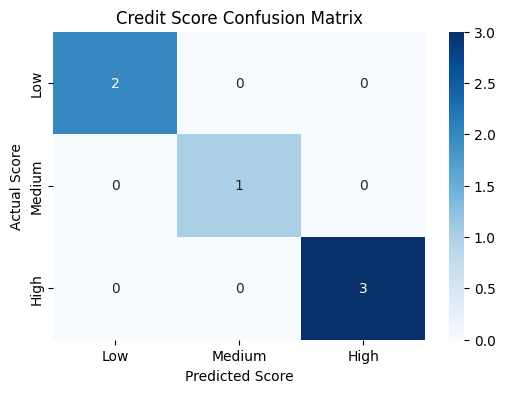

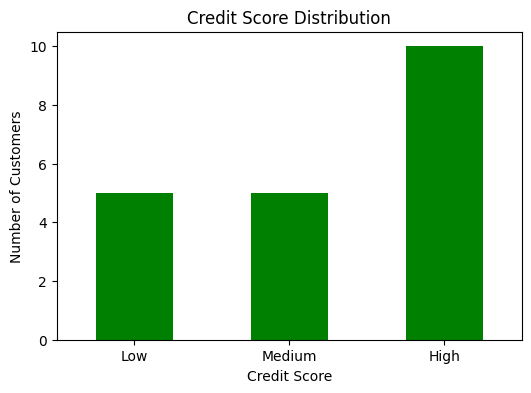


Classification Report:
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00         2
      Medium       1.00      1.00      1.00         1
        High       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6


New Customer Credit Score: High


In [1]:
# Experiment No: 11
# Question: Write a program for the task of Credit Score Classification.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create Dataset
data = {
    'Income': [25000, 40000, 60000, 80000, 30000, 70000, 90000, 35000,
               55000, 100000, 45000, 65000, 28000, 85000, 50000,
               75000, 32000, 95000, 58000, 72000],

    'Debt': [20000, 15000, 10000, 5000, 25000, 12000, 4000, 22000,
             14000, 3000, 18000, 9000, 26000, 6000, 16000,
             8000, 24000, 3500, 13000, 7000],

    'Payment_History': ['Poor', 'Average', 'Good', 'Good', 'Poor',
                        'Good', 'Good', 'Poor', 'Average', 'Good',
                        'Average', 'Good', 'Poor', 'Good', 'Average',
                        'Good', 'Poor', 'Good', 'Average', 'Good'],

    'Credit_Score': ['Low', 'Medium', 'High', 'High', 'Low',
                     'High', 'High', 'Low', 'Medium', 'High',
                     'Medium', 'High', 'Low', 'High', 'Medium',
                     'High', 'Low', 'High', 'Medium', 'High']
}

df = pd.DataFrame(data)

# Convert Categorical Values
df['Payment_History'] = df['Payment_History'].map({
    'Poor': 0, 'Average': 1, 'Good': 2
})

df['Credit_Score'] = df['Credit_Score'].map({
    'Low': 0, 'Medium': 1, 'High': 2
})

# Features and Target
X = df[['Income', 'Debt', 'Payment_History']]
y = df['Credit_Score']

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Train Decision Tree Model
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Actual Credit Scores:", list(y_test))
print("Predicted Credit Scores:", list(y_pred))
print("\nAccuracy:", round(accuracy * 100, 2), "%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.xlabel("Predicted Score")
plt.ylabel("Actual Score")
plt.title("Credit Score Confusion Matrix")
plt.show()

# Credit Score Distribution Graph
plt.figure(figsize=(6, 4))
df['Credit_Score'].value_counts().sort_index().plot(
    kind='bar', color='green'
)

plt.xticks([0, 1, 2], ['Low', 'Medium', 'High'], rotation=0)
plt.xlabel("Credit Score")
plt.ylabel("Number of Customers")
plt.title("Credit Score Distribution")
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['Low', 'Medium', 'High'],
    zero_division=0
))

# Test New Customer
new_customer = pd.DataFrame({
    'Income': [60000],
    'Debt': [10000],
    'Payment_History': [2]
})

prediction = model.predict(new_customer)[0]

scores = {0: 'Low', 1: 'Medium', 2: 'High'}

print("\nNew Customer Credit Score:", scores[prediction])

Accuracy: 100.0 %

Actual Values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Predicted Values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


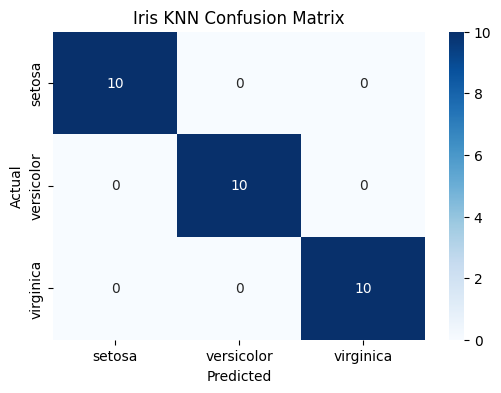

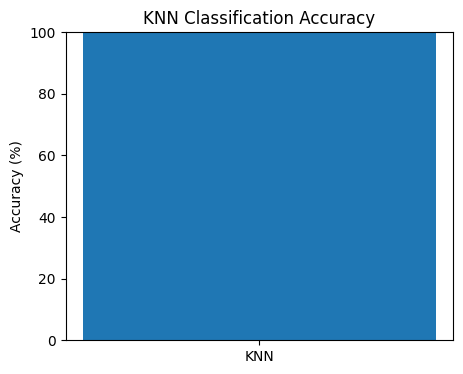


Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

New Flower Prediction: setosa


In [2]:
# Experiment No: 12
# Question: Implement Iris Flower Classification using KNN.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load Iris Dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create KNN Model
model = KNeighborsClassifier(n_neighbors=5)

# Train Model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Display Accuracy
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nActual Values:", y_test)
print("Predicted Values:", y_pred)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Iris KNN Confusion Matrix")
plt.show()

# Accuracy Graph
plt.figure(figsize=(5, 4))
plt.bar(['KNN'], [accuracy_score(y_test, y_pred) * 100])
plt.ylabel("Accuracy (%)")
plt.title("KNN Classification Accuracy")
plt.ylim(0, 100)
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

# Predict New Flower
new_flower = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(new_flower)

print("New Flower Prediction:", iris.target_names[prediction[0]])

Car Dataset:
    Year  Kilometers  Fuel    Price
0   2015       50000     0   400000
1   2017       30000     1   550000
2   2018       25000     0   600000
3   2016       60000     1   450000
4   2019       20000     0   750000
5   2020       15000     0   850000
6   2014       80000     1   300000
7   2021       10000     0   950000
8   2018       35000     1   650000
9   2017       45000     0   500000
10  2022        8000     0  1100000
11  2016       65000     1   420000
12  2019       22000     0   780000
13  2020       18000     0   900000
14  2015       70000     1   350000
15  2021       12000     0  1000000

Actual Prices: [400000, 550000, 850000, 350000]
Predicted Prices: [295919.4  515771.4  859399.21 349076.81]

Mean Absolute Error: 37157.9
Mean Squared Error: 3023391463.19
R2 Score: 0.92

Predicted Car Price: Rs. 1105109.44


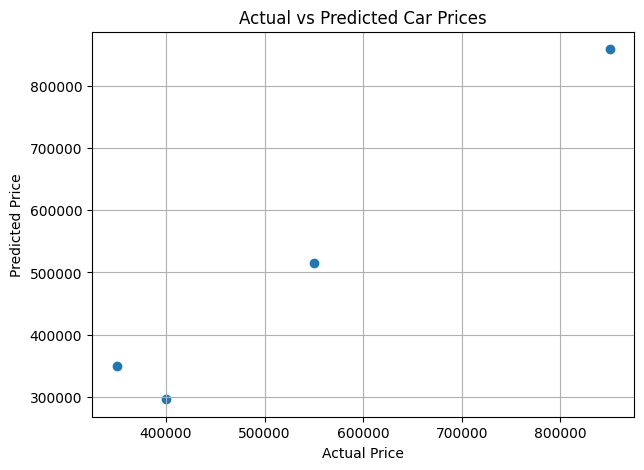

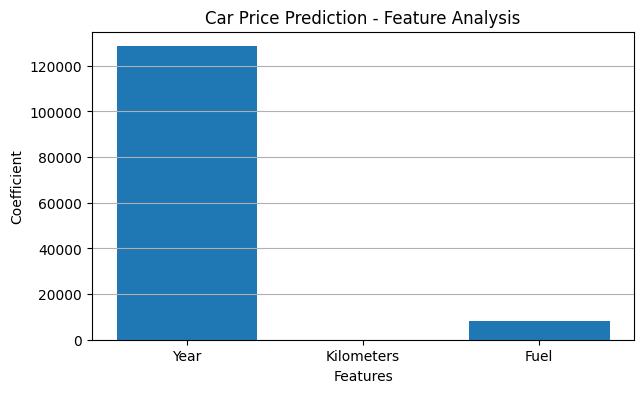

In [3]:
# Experiment No: 13
# Question: Implement the Car Price Prediction Model using Python.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create Dataset
data = {
    'Year': [2015, 2017, 2018, 2016, 2019, 2020, 2014, 2021,
             2018, 2017, 2022, 2016, 2019, 2020, 2015, 2021],
    'Kilometers': [50000, 30000, 25000, 60000, 20000, 15000, 80000, 10000,
                   35000, 45000, 8000, 65000, 22000, 18000, 70000, 12000],
    'Fuel': [0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0],
    'Price': [400000, 550000, 600000, 450000, 750000, 850000, 300000, 950000,
              650000, 500000, 1100000, 420000, 780000, 900000, 350000, 1000000]
}

df = pd.DataFrame(data)

# Display Dataset
print("Car Dataset:")
print(df)

# Features and Target
X = df[['Year', 'Kilometers', 'Fuel']]
y = df['Price']

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Train Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Display Results
print("\nActual Prices:", list(y_test))
print("Predicted Prices:", y_pred.round(2))

# Evaluation
print("\nMean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))
print("Mean Squared Error:", round(mean_squared_error(y_test, y_pred), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 2))

# Predict New Car Price
new_car = pd.DataFrame({
    'Year': [2022],
    'Kilometers': [10000],
    'Fuel': [0]
})

predicted_price = model.predict(new_car)

print("\nPredicted Car Price: Rs.", round(predicted_price[0], 2))

# Actual vs Predicted Graph
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")
plt.grid(True)
plt.show()

# Feature Importance Graph
plt.figure(figsize=(7, 4))
plt.bar(X.columns, model.coef_)
plt.xlabel("Features")
plt.ylabel("Coefficient")
plt.title("Car Price Prediction - Feature Analysis")
plt.grid(axis='y')
plt.show()

House Price Dataset:
    Area  Bedrooms  Age    Price
0   1000         2   10  2500000
1   1200         2    8  3000000
2   1500         3    5  4000000
3   1800         3    7  4500000
4   2000         3    4  5000000
5   2200         4    3  6000000
6   2500         4    2  7000000
7   2800         4    1  7500000
8   3000         5    2  8500000
9   1100         2   12  2700000
10  1600         3    6  4200000
11  2100         4    5  5800000
12  2400         4    3  6800000
13  2700         5    2  7800000
14  1900         3    8  4600000
15  2300         4    4  6200000

Actual Prices: [2500000, 3000000, 6000000, 4600000]
Predicted Prices: [2305321.99 2764504.81 6111097.97 4928212.27]

Mean Absolute Error: 217370.86
Mean Squared Error: 53355891555.91
R2 Score: 0.97

Predicted House Price: Rs. 5143924.54


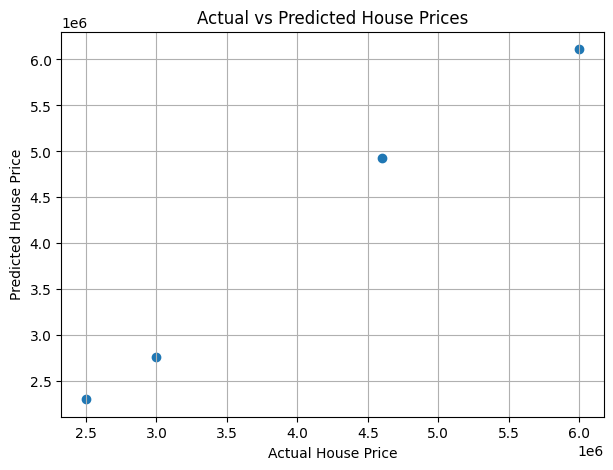

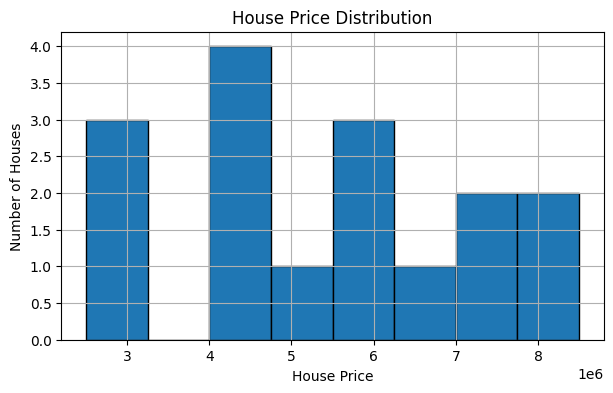

In [4]:
# Experiment No: 14
# Question: Implement House Price Prediction using appropriate
# machine learning algorithm.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create Dataset
data = {
    'Area': [1000, 1200, 1500, 1800, 2000, 2200, 2500, 2800,
             3000, 1100, 1600, 2100, 2400, 2700, 1900, 2300],
    'Bedrooms': [2, 2, 3, 3, 3, 4, 4, 4,
                 5, 2, 3, 4, 4, 5, 3, 4],
    'Age': [10, 8, 5, 7, 4, 3, 2, 1,
            2, 12, 6, 5, 3, 2, 8, 4],
    'Price': [2500000, 3000000, 4000000, 4500000,
              5000000, 6000000, 7000000, 7500000,
              8500000, 2700000, 4200000, 5800000,
              6800000, 7800000, 4600000, 6200000]
}

df = pd.DataFrame(data)

# Display Dataset
print("House Price Dataset:")
print(df)

# Features and Target
X = df[['Area', 'Bedrooms', 'Age']]
y = df['Price']

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Train Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict House Prices
y_pred = model.predict(X_test)

# Display Results
print("\nActual Prices:", list(y_test))
print("Predicted Prices:", y_pred.round(2))

# Model Evaluation
print("\nMean Absolute Error:",
      round(mean_absolute_error(y_test, y_pred), 2))

print("Mean Squared Error:",
      round(mean_squared_error(y_test, y_pred), 2))

print("R2 Score:", round(r2_score(y_test, y_pred), 2))

# Predict New House Price
new_house = pd.DataFrame({
    'Area': [2000],
    'Bedrooms': [3],
    'Age': [5]
})

price = model.predict(new_house)

print("\nPredicted House Price: Rs.", round(price[0], 2))

# Actual vs Predicted Graph
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")
plt.grid(True)
plt.show()

# House Price Distribution
plt.figure(figsize=(7, 4))
plt.hist(df['Price'], bins=8, edgecolor='black')
plt.xlabel("House Price")
plt.ylabel("Number of Houses")
plt.title("House Price Distribution")
plt.grid(True)
plt.show()

Actual Values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Predicted Values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]

Accuracy: 96.67 %

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


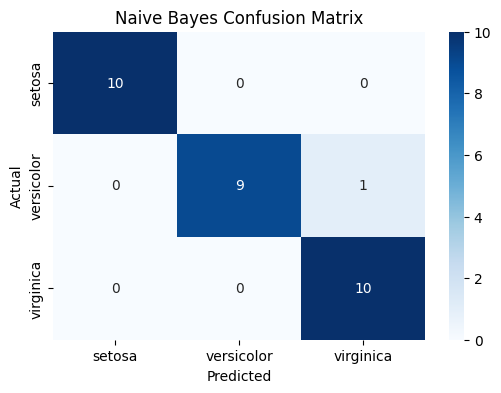

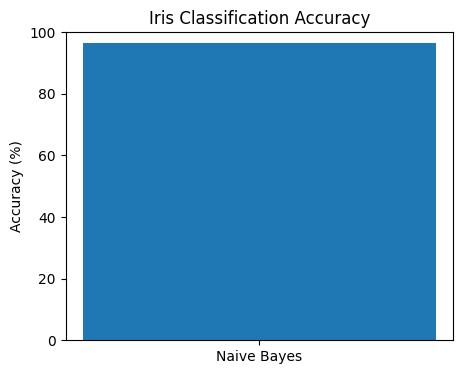


Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


New Flower Prediction: setosa


In [5]:
# Experiment No: 15
# Question: Implement Iris Flower Classification using Naive Bayes classifier.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load Iris Dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create Naive Bayes Model
model = GaussianNB()

# Train Model
model.fit(X_train, y_train)

# Predict Results
y_pred = model.predict(X_test)

# Display Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Actual Values:", y_test)
print("Predicted Values:", y_pred)
print("\nAccuracy:", round(accuracy * 100, 2), "%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Naive Bayes Confusion Matrix")
plt.show()

# Accuracy Graph
plt.figure(figsize=(5, 4))
plt.bar(['Naive Bayes'], [accuracy * 100])
plt.ylabel("Accuracy (%)")
plt.title("Iris Classification Accuracy")
plt.ylim(0, 100)
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=iris.target_names
))

# Predict New Flower
new_flower = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(new_flower)

print("\nNew Flower Prediction:",
      iris.target_names[prediction[0]])


Algorithm: KNN
Accuracy: 93.33 %
Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Algorithm: Decision Tree
Accuracy: 93.33 %
Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Algorithm: Naive Bayes
Accuracy: 96.67 %
Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Algorithm: Logistic Regression
Accuracy: 93.33 %
Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Algorithm Performance Comparison:
KNN : 93.33 %
Decision Tree : 93.33 %
Naive Bayes : 96.67 %
Logistic Regression : 93.33 %


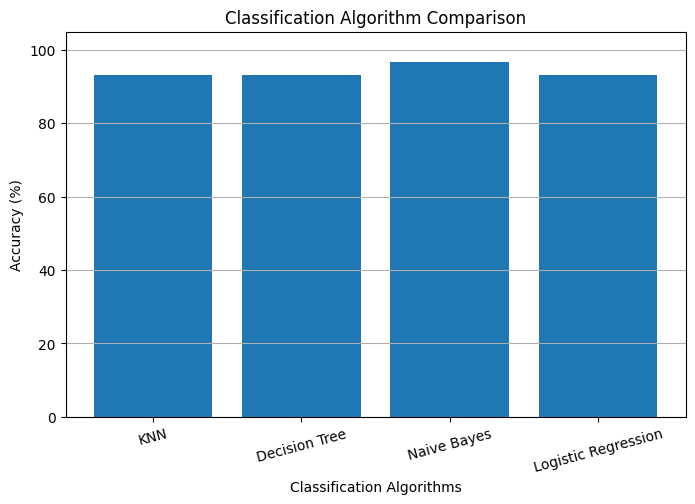

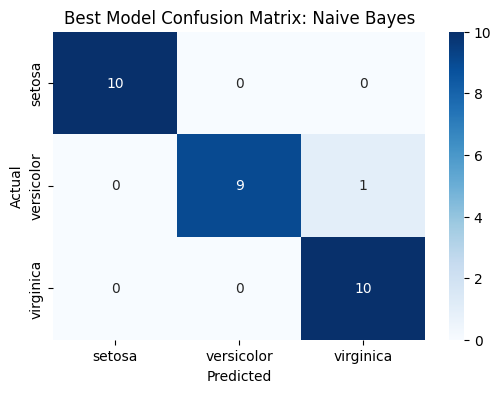


Best Classification Algorithm: Naive Bayes
Best Accuracy: 96.67 %


In [6]:
# Experiment No: 16
# Question: Compare different types of Classification Algorithms
# and evaluate their performance.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load Dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Classification Algorithms
models = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Naive Bayes': GaussianNB(),
    'Logistic Regression': LogisticRegression(max_iter=200)
}

# Train and Evaluate Models
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy * 100

    print("\nAlgorithm:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

# Display Comparison
print("\nAlgorithm Performance Comparison:")
for name, score in results.items():
    print(name, ":", round(score, 2), "%")

# Accuracy Comparison Graph
plt.figure(figsize=(8, 5))
plt.bar(results.keys(), results.values())
plt.xlabel("Classification Algorithms")
plt.ylabel("Accuracy (%)")
plt.title("Classification Algorithm Comparison")
plt.ylim(0, 105)
plt.xticks(rotation=15)
plt.grid(axis='y')
plt.show()

# Confusion Matrix of Best Model
best_name = max(results, key=results.get)
best_model = models[best_name]
best_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Best Model Confusion Matrix: " + best_name)
plt.show()

# Best Algorithm
print("\nBest Classification Algorithm:", best_name)
print("Best Accuracy:", round(results[best_name], 2), "%")

Mobile Dataset:
   RAM  ROM  Battery  Camera  Price
0    2   32     3000       8   5000
1    3   32     3500      12   7000
2    4   64     4000      13  10000
3    4  128     4500      16  12000
4    6   64     4000      16  15000
5    6  128     5000      48  18000
6    8  128     4500      48  22000
7    8  256     5000      64  28000
8   12  256     5000      64  35000
9   12  512     6000     108  45000

Mean Absolute Error: 3100.0
Mean Squared Error: 17227600.0
R2 Score: 0.91

Predicted Mobile Price: Rs. 23470.0


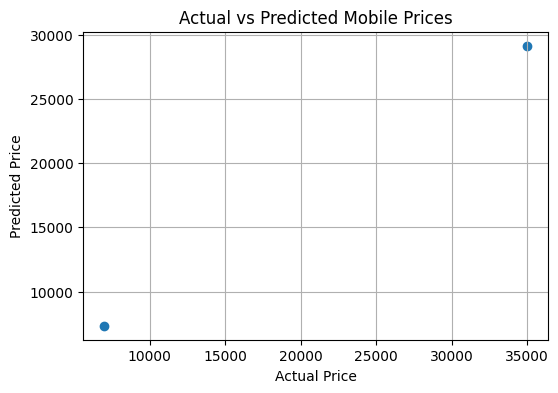

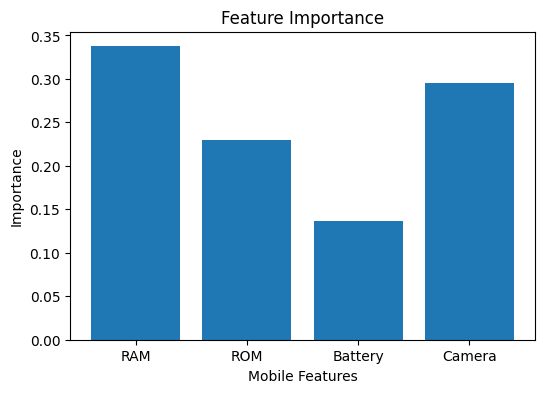

In [7]:
# Experiment No: 17
# Question: Implement Mobile Price Prediction using appropriate
# machine learning algorithm.

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create Mobile Dataset
data = {
    'RAM': [2, 3, 4, 4, 6, 6, 8, 8, 12, 12],
    'ROM': [32, 32, 64, 128, 64, 128, 128, 256, 256, 512],
    'Battery': [3000, 3500, 4000, 4500, 4000, 5000, 4500, 5000, 5000, 6000],
    'Camera': [8, 12, 13, 16, 16, 48, 48, 64, 64, 108],
    'Price': [5000, 7000, 10000, 12000, 15000, 18000, 22000, 28000, 35000, 45000]
}

df = pd.DataFrame(data)

print("Mobile Dataset:")
print(df)

# Separate Features and Target
X = df[['RAM', 'ROM', 'Battery', 'Camera']]
y = df['Price']

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predict Prices
y_pred = model.predict(X_test)

# Evaluate Model
print("\nMean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))
print("Mean Squared Error:", round(mean_squared_error(y_test, y_pred), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 2))

# Predict New Mobile Price
new_mobile = pd.DataFrame(
    [[8, 128, 5000, 64]],
    columns=['RAM', 'ROM', 'Battery', 'Camera']
)

price = model.predict(new_mobile)
print("\nPredicted Mobile Price: Rs.", round(price[0], 2))

# Actual vs Predicted Graph
plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Mobile Prices")
plt.grid()
plt.show()

# Feature Importance Graph
plt.figure(figsize=(6, 4))
plt.bar(X.columns, model.feature_importances_)
plt.xlabel("Mobile Features")
plt.ylabel("Importance")
plt.title("Feature Importance")
plt.show()

Actual Values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Predicted Values: [0 2 1 1 0 2 0 0 2 1 2 2 2 2 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]

Accuracy: 86.67 %

Confusion Matrix:
[[10  0  0]
 [ 0  7  3]
 [ 0  1  9]]


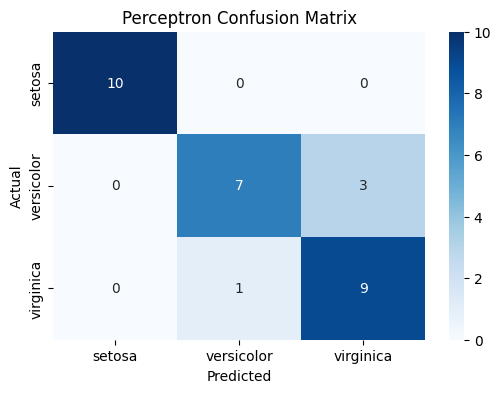

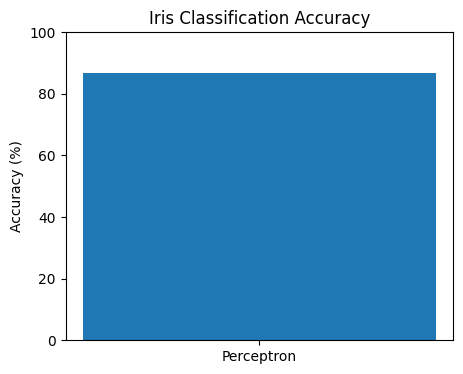


Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.88      0.70      0.78        10
   virginica       0.75      0.90      0.82        10

    accuracy                           0.87        30
   macro avg       0.88      0.87      0.87        30
weighted avg       0.88      0.87      0.87        30


Predicted Flower: setosa


In [8]:
# Experiment No: 18
# Question: Implement Perceptron based IRIS classification.

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load Iris Dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create and Train Perceptron Model
model = Perceptron(max_iter=1000, eta0=0.1, random_state=42)
model.fit(X_train, y_train)

# Predict Results
y_pred = model.predict(X_test)

# Display Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Actual Values:", y_test)
print("Predicted Values:", y_pred)
print("\nAccuracy:", round(accuracy * 100, 2), "%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Perceptron Confusion Matrix")
plt.show()

# Accuracy Graph
plt.figure(figsize=(5, 4))
plt.bar(['Perceptron'], [accuracy * 100])
plt.ylabel("Accuracy (%)")
plt.title("Iris Classification Accuracy")
plt.ylim(0, 100)
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

# Predict New Flower
new_flower = [[5.1, 3.5, 1.4, 0.2]]
new_flower = scaler.transform(new_flower)

prediction = model.predict(new_flower)
print("\nPredicted Flower:", iris.target_names[prediction[0]])

Bank Loan Dataset:
    Age  Income  Credit_Score Loan_Approved
0    25   25000           550            No
1    30   30000           600            No
2    35   40000           650           Yes
3    40   50000           700           Yes
4    45   60000           750           Yes
5    50   70000           780           Yes
6    28   28000           580            No
7    32   35000           620            No
8    38   45000           680           Yes
9    48   75000           790           Yes
10   26   22000           540            No
11   36   42000           660           Yes
12   42   55000           720           Yes
13   55   80000           800           Yes
14   29   32000           610            No
15   33   38000           640            No
16   47   65000           760           Yes
17   52   85000           810           Yes
18   31   33000           630            No
19   44   58000           730           Yes

Actual Values: ['No' 'No' 'Yes' 'Yes']
Predicted Values:

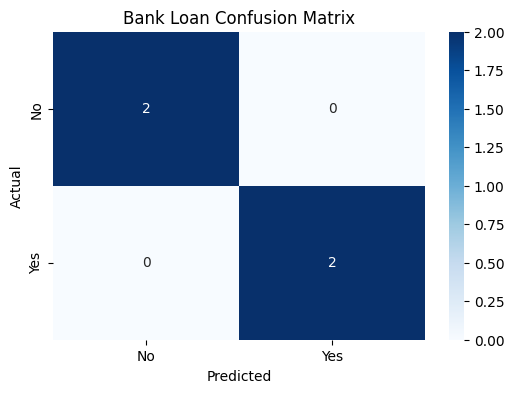

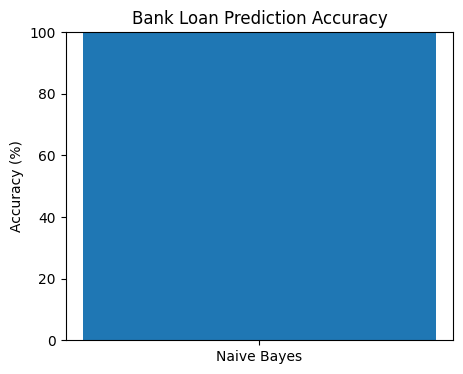


Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         2
         Yes       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4


New Customer Loan Status: Yes


In [9]:
# Experiment No: 19
# Question: Implementation of Naive Bayes classification
# for Bank Loan prediction.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create Bank Loan Dataset
data = {
    'Age': [25, 30, 35, 40, 45, 50, 28, 32, 38, 48,
            26, 36, 42, 55, 29, 33, 47, 52, 31, 44],
    'Income': [25000, 30000, 40000, 50000, 60000,
               70000, 28000, 35000, 45000, 75000,
               22000, 42000, 55000, 80000, 32000,
               38000, 65000, 85000, 33000, 58000],
    'Credit_Score': [550, 600, 650, 700, 750, 780, 580, 620,
                     680, 790, 540, 660, 720, 800, 610,
                     640, 760, 810, 630, 730],
    'Loan_Approved': ['No', 'No', 'Yes', 'Yes', 'Yes',
                      'Yes', 'No', 'No', 'Yes', 'Yes',
                      'No', 'Yes', 'Yes', 'Yes', 'No',
                      'No', 'Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

print("Bank Loan Dataset:")
print(df)

# Encode Target Values
encoder = LabelEncoder()
y = encoder.fit_transform(df['Loan_Approved'])

# Select Features
X = df[['Age', 'Income', 'Credit_Score']]

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train Naive Bayes Model
model = GaussianNB()
model.fit(X_train, y_train)

# Predict Results
y_pred = model.predict(X_test)

# Evaluate Model
accuracy = accuracy_score(y_test, y_pred)

print("\nActual Values:", encoder.inverse_transform(y_test))
print("Predicted Values:", encoder.inverse_transform(y_pred))
print("\nAccuracy:", round(accuracy * 100, 2), "%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Bank Loan Confusion Matrix")
plt.show()

# Accuracy Graph
plt.figure(figsize=(5, 4))
plt.bar(['Naive Bayes'], [accuracy * 100])
plt.ylabel("Accuracy (%)")
plt.title("Bank Loan Prediction Accuracy")
plt.ylim(0, 100)
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=encoder.classes_,
    zero_division=0
))

# Predict New Customer
new_customer = pd.DataFrame(
    [[35, 45000, 680]],
    columns=['Age', 'Income', 'Credit_Score']
)

prediction = model.predict(new_customer)

print("\nNew Customer Loan Status:",
      encoder.inverse_transform(prediction)[0])

Sales Dataset:
    Month  Sales
0       1    100
1       2    120
2       3    115
3       4    140
4       5    150
5       6    160
6       7    155
7       8    180
8       9    190
9      10    200
10     11    210
11     12    230

Mean Absolute Error: 2.43
Mean Squared Error: 6.5
R2 Score: 1.0

Future Sales Prediction:
Month 13 : 235.82
Month 14 : 247.01
Month 15 : 258.2


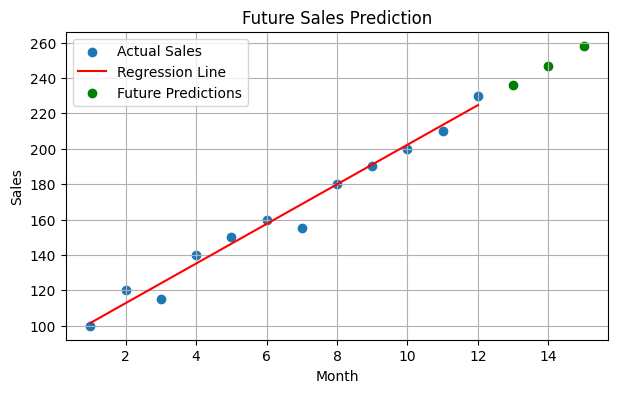

In [10]:
# Experiment No: 20
# Question: Implement Future Sales Prediction using a suitable
# machine learning algorithm.

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Create Sales Dataset
data = {
    'Month': list(range(1, 13)),
    'Sales': [100, 120, 115, 140, 150, 160,
              155, 180, 190, 200, 210, 230]
}

df = pd.DataFrame(data)

print("Sales Dataset:")
print(df)

# Features and Target
X = df[['Month']]
y = df['Sales']

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict Sales
y_pred = model.predict(X_test)

# Evaluate Model
print("\nMean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))
print("Mean Squared Error:", round(mean_squared_error(y_test, y_pred), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 2))

# Predict Future Sales
future_months = pd.DataFrame({'Month': [13, 14, 15]})
future_sales = model.predict(future_months)

print("\nFuture Sales Prediction:")
for month, sales in zip(future_months['Month'], future_sales):
    print("Month", month, ":", round(sales, 2))

# Sales Prediction Graph
plt.figure(figsize=(7, 4))
plt.scatter(X, y, label='Actual Sales')
plt.plot(X, model.predict(X), color='red', label='Regression Line')
plt.scatter(future_months, future_sales, color='green',
            label='Future Predictions')

plt.xlabel("Month")
plt.ylabel("Sales")
plt.title("Future Sales Prediction")
plt.legend()
plt.grid()
plt.show()